# 🕵️ The Attention Detective: Build a Transformer, Then Give It a Tiny Upgrade
### CS/SE 4AL3 — Interactive PyTorch tutorial
**Mission:** Investigate how words share information, then add a lightweight adapter to a pretrained Transformer. No giant datasets and no hours of training.



Setup
Recommended: Python 3.10–3.12 and a fresh virtual environment. Run the install cell only if needed. **AdapterHub's current library is `adapters`, not the old `adapter-transformers` package.**

In [1]:
# Run only if a package is missing (then restart the kernel).
# %pip install -q torch matplotlib numpy
# For the optional pretrained example in Section 6: %pip install -q adapters

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(7)
print('PyTorch:', torch.__version__, '| CPU demo ready')

PyTorch: 2.15.0 | CPU demo ready


## 1. 🎭 Who is “it”? 

From Lecture 25: **“The chicken didn't cross the road because it was too tired.”** Switch *tired* to *wide*. What does *it* refer to now?

**Vote before running code:** In each sentence, which words should *it* look at? A Transformer does not receive a built-in pronoun-resolution rule: it learns ways to combine token representations from data. Attention weights alone are **not** a faithful explanation of model reasoning.

We begin with **deliberately handcrafted** 2D vectors — a toy demonstration of the attention calculation, *not a trained language model*.

In [2]:
tokens = ['chicken', 'road', 'it']
# 2D features: [animal-ish, location-ish]. Built solely to make the math visible.
X = torch.tensor([[2., 0.], [0., 2.], [1., 0.]])
print('tokens:', tokens)
print('X shape:', tuple(X.shape), '(sequence_length, d_model)')

tokens: ['chicken', 'road', 'it']
X shape: (3, 2) (sequence_length, d_model)


So now, we represented three tokens each with a 2-dimensional vector (2 features).

Dimension 1: Animal-related 

Dimension 2: Location-related

## 2. 🔎 Q, K, V: the detective board

Q: Queries : What information am I searching for?

K: Keys : What properties make this piece of information relevant?

V: Values : What information should I retrieve if it matches?


$$
Q = XW_Q,\quad K = XW_K,\quad V = XW_V
$$

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

In actual training, the projection matrices are learned. We use identity matrices to expose the computation. Each **row** of the heatmap is a querying token; each **column** is a key token.

Why do we need three different matrices?
Why not just use the input embedding \(X\) directly?

Because different mathematical representations can serve different purposes.

Suppose we want a token to find another token using grammatical relationships. Its query and key projections can learn features useful for matching.

But the information ultimately transferred through the value vectors may need a different representation.

Having separate projections lets the model learn these operations independently.

In [3]:
def attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:  # True = allowed to attend
        scores = scores.masked_fill(~mask, float('-inf'))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights, scores

Wq = Wk = Wv = torch.eye(2)
Q, K, V = X @ Wq, X @ Wk, X @ Wv
Z, A, S = attention(Q, K, V)
print('Q, K, V:', Q.shape, K.shape, V.shape)
print('scores shape:', S.shape, 'weights shape:', A.shape, 'output shape:', Z.shape)
print('Attention weights (rows add to 1):\n', A.round(decimals=3))
assert torch.allclose(A.sum(-1), torch.ones(len(tokens)))

Q, K, V: torch.Size([3, 2]) torch.Size([3, 2]) torch.Size([3, 2])
scores shape: torch.Size([3, 3]) weights shape: torch.Size([3, 3]) output shape: torch.Size([3, 2])
Attention weights (rows add to 1):
 tensor([[0.7680, 0.0450, 0.1870],
        [0.0530, 0.8940, 0.0530],
        [0.5760, 0.1400, 0.2840]])


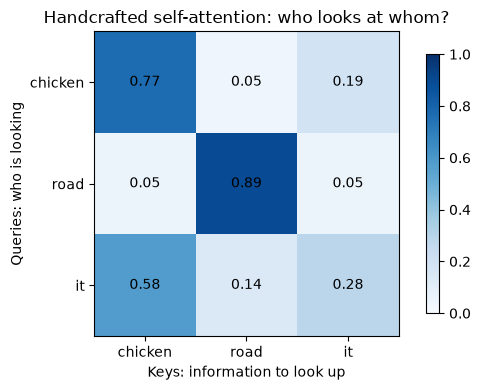

In [4]:
import numpy 
def show_heatmap(weights, labels, title='Attention map'):
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(weights.detach().cpu(), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel('Keys: information to look up')
    ax.set_ylabel('Queries: who is looking')
    ax.set_title(title)
    for (r, c), value in np.ndenumerate(weights.detach().cpu().numpy()):
        ax.text(c, r, f'{value:.2f}', ha='center', va='center', color='black')
    fig.colorbar(im, ax=ax, shrink=.85)
    plt.tight_layout()
    plt.show()

show_heatmap(A, tokens, 'Handcrafted self-attention: who looks at whom?')

**Prediction game:** What happens if we multiply the query vector for `it` by 4? Does its distribution become more or less peaked? Change `4` to `0.25`, rerun, and explain **why**.

Original it weights: [0.5759999752044678, 0.14000000059604645, 0.2840000092983246]
Modified it weights: [0.39399999380111694, 0.2759999930858612, 0.33000001311302185]


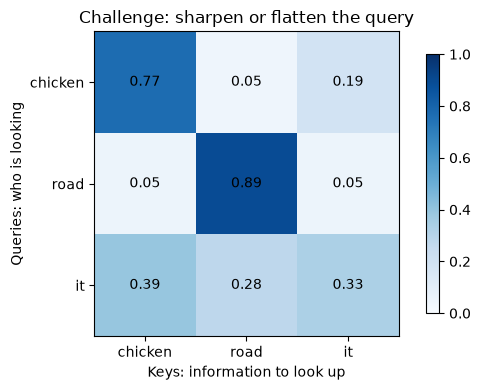

In [18]:
Q_experiment = Q.clone()
Q_experiment[2] *= 0.25  # TODO: try 0.25 instead of 4
_, A_experiment, _ = attention(Q_experiment, K, V)
print('Original it weights:', A[2].round(decimals=3).tolist())
print('Modified it weights:', A_experiment[2].round(decimals=3).tolist())
show_heatmap(A_experiment, tokens, 'Challenge: sharpen or flatten the query')

The query's magnitude affects attention distribution sharpness, while its direction influences which keys receive high scores.

**Checkpoint:** Softmax normalizes *within each query row*. The square-root scaling keeps dot products from growing excessively with key dimension.

### Try PyTorch's built-in attention

`F.scaled_dot_product_attention` implements the core operation. We add batch and head dimensions (both 1).

In [ ]:
built_in = F.scaled_dot_product_attention(Q[None,None], K[None,None], V[None,None])[0,0]
print('Manual == PyTorch:', torch.allclose(built_in, Z, atol=1e-6))
assert torch.allclose(built_in, Z, atol=1e-6)

Manual == PyTorch: True


## 3. 🚨 The future-information leak

**Question:** If a model predicts the next word, can token 1 peek at token 3? **No.** A causal mask blocks future tokens *before* softmax.

Encoder-only, bidirectional models such as BERT typically allow both directions. Autoregressive decoder self-attention uses a causal mask. This resolves a common confusion: *self-attention does not automatically mean only attending to previous words*.

**Visual checkpoint:** Compare bidirectional attention (all tokens visible) with causal attention (future tokens hidden).

Let's build the causal mask

Allowed positions (1 = visible):
 tensor([[1, 0, 0],
        [1, 1, 0],
        [1, 1, 1]], dtype=torch.int32)


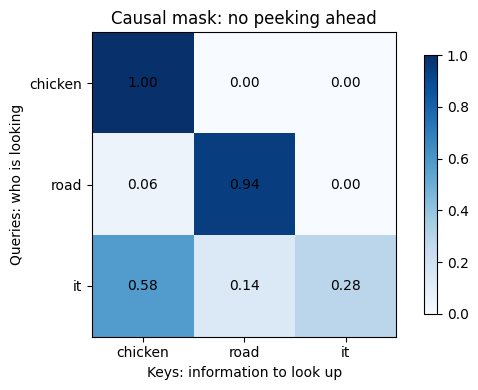

In [ ]:
n_tokens = len(tokens)
causal = torch.ones(n_tokens, n_tokens, dtype=torch.bool).tril() #keep the lower triangle (including diagonal) as True
_, A_causal, _ = attention(Q, K, V, mask=causal)
print('Allowed positions (1 = visible):\n', causal.int())
show_heatmap(A_causal, tokens, 'Causal mask: no peeking ahead')
assert torch.all(A_causal.triu(diagonal=1) == 0)

### Two heads = two detectives

Different heads have separate learned Q/K/V projections. In this small **untrained** example, they need not learn human-interpretable specialties. Try changing the seed and compare the patterns.

**Visual checkpoint:** In multi-head attention, each head has its own learned projections and attention map.

Input: torch.Size([1, 3, 4]) | Output: torch.Size([1, 3, 4]) | Weights: torch.Size([1, 2, 3, 3])


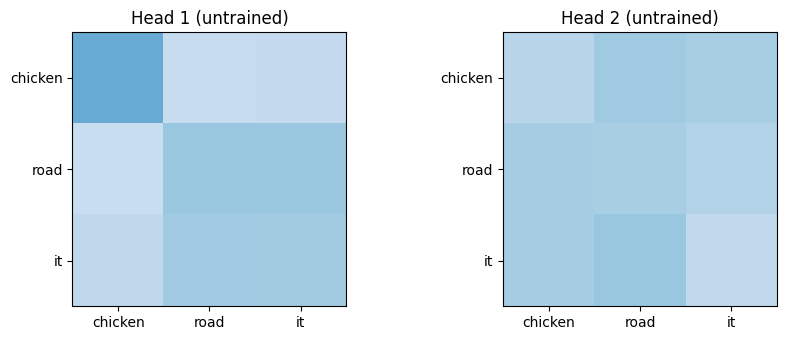

In [ ]:
torch.manual_seed(12)
mha = nn.MultiheadAttention(embed_dim=4, num_heads=2, batch_first=True)
x4 = torch.randn(1, len(tokens), 4)
out, head_weights = mha(x4, x4, x4, need_weights=True, average_attn_weights=False)
print('Input:', x4.shape, '| Output:', out.shape, '| Weights:', head_weights.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for h, ax in enumerate(axes):
    im = ax.imshow(head_weights[0, h].detach(), vmin=0, vmax=1, cmap='Blues')
    ax.set_title(f'Head {h+1} (untrained)')
    ax.set_xticks(range(len(tokens)), tokens)
    ax.set_yticks(range(len(tokens)), tokens)
plt.tight_layout(); plt.show()

**Visual checkpoint:** Attention maps are learned; random initial weights are not linguistic explanations.

## 4. 🧱 Build an actual Transformer encoder block

Lecture 25: **multi-head attention → add & norm → feedforward → add & norm**

The feedforward network transforms each token independently; *attention* is the component that mixes information across token positions.

In [ ]:
class MiniTransformerBlock(nn.Module):
    def __init__(self, d_model=16, n_heads=4, expansion=2):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, expansion*d_model),
                                 nn.GELU(), nn.Linear(expansion*d_model, d_model))

    def forward(self, x, causal=False):
        mask = torch.triu(torch.ones(x.size(1), x.size(1),
                            device=x.device, dtype=torch.bool), diagonal=1) if causal else None
        a, weights = self.attn(self.norm1(x), self.norm1(x), self.norm1(x),
                               attn_mask=mask, need_weights=True)
        x = x + a                       # residual #1
        x = x + self.ffn(self.norm2(x)) # residual #2
        return x, weights

block = MiniTransformerBlock()
hidden = torch.randn(2, 5, 16)  # batch, sequence, feature dimension
result, weights = block(hidden)
print('Input:', tuple(hidden.shape), '-> output:', tuple(result.shape))
print('Block parameters:', sum(p.numel() for p in block.parameters()))
assert result.shape == hidden.shape

Input: (2, 5, 16) -> output: (2, 5, 16)
Block parameters: 2224


![Transformer Architecture](images/som.png)

**Visual checkpoint:** A Transformer block combines attention, residual connections, normalization and a feedforward network.

### 🎲 Word-order challenge

Without positions, a self-attention encoder block is permutation-equivariant: if we shuffle input tokens, its outputs shuffle the same way. With **positional embeddings added**, swapping words while keeping positional indices fixed generally changes their representations in a non-trivial way.

This is why Transformers need a way to know word order. Compare the maximum differences (should be near zero without positions).

We will create 4 tokens, each with 16 features, then shuffle their order. Then the Transformer processes both sequences.

Permutation error measures how much the Transformer's outputs change when we shuffle the input tokens, after rearranging the outputs back into corresponding order.

In [ ]:
block.eval()
x = torch.randn(1, 4, 16)
perm = torch.tensor([2, 0, 3, 1])
with torch.no_grad():
    a, _ = block(x)
    b, _ = block(x[:, perm])
    print('Without positions, permutation error:', (a[:, perm] - b).abs().max().item())

position_table = nn.Embedding(4, 16)
pos = position_table(torch.arange(4))[None]
with torch.no_grad():
    a_pos, _ = block(x + pos)
    b_pos, _ = block(x[:, perm] + pos)
print('With fixed positions, permutation error:', (a_pos[:, perm] - b_pos).abs().max().item())

Without positions, permutation error: 1.1920928955078125e-07
With fixed positions, permutation error: 3.7362799644470215


I'm testing whether the Transformer is sensitive to word order. I process four tokens, shuffle their order, and process them again.

Without positional embeddings, the output simply follows the same shuffle. After aligning the outputs, the maximum difference is almost zero.

But when I add positional embeddings, moving a token changes its positional information. The output no longer just follows the shuffle, and our error becomes much larger.

This demonstrates why Transformers need positional information to distinguish different token orders.

## 5. 🧩 The mini-upgrade: an adapter
Lecture 26 introduces **bottleneck adapters** as a parameter-efficient way to adapt a large pretrained model: keep its main weights frozen and train small inserted modules.

First build one ourselves to see the mechanics, then use the real **AdapterHub / `adapters`** library. This is distinct from LoRA, which learns low-rank updates to existing weights rather than using the same bottleneck module below.

An adapter can compute $h + W_{up}\,\sigma(W_{down}h)$, where $d_{bottleneck} \ll d_{model}$.

In [ ]:
class BottleneckAdapter(nn.Module):
    def __init__(self, d_model=16, bottleneck=4):
        super().__init__()
        self.down = nn.Linear(d_model, bottleneck)
        self.up = nn.Linear(bottleneck, d_model)
        nn.init.zeros_(self.up.weight)  # start as near-identity (bias also set to zero)
        nn.init.zeros_(self.up.bias)

    def forward(self, x):
        return x + self.up(F.relu(self.down(x)))

adapter = BottleneckAdapter()
with torch.no_grad():
    adapted = adapter(result)
print('Preserved shape:', tuple(adapted.shape))
print('Parameters in mini Transformer block:', sum(p.numel() for p in block.parameters()))
print('Parameters in ONE adapter:', sum(p.numel() for p in adapter.parameters()))
print('Initially identical?', torch.allclose(result, adapted))
assert torch.allclose(result, adapted)

Preserved shape: (2, 5, 16)
Parameters in mini Transformer block: 2224
Parameters in ONE adapter: 148
Initially identical? True


Down projection: "We reduce the feature dimension from 16 to 4. This forces the adapter to learn its modification through a small representation."

ReLU: "We introduce nonlinearity. Without it, the two linear projections would collapse into a single affine transformation."

Up projection: "We transform the four hidden features back to 16 so the result can be added to the original Transformer representation."

Residual addition: "Instead of replacing what the Transformer knows, we learn a correction to its output."

### 🧭 Where does the adapter go? (architecture + roles)

The **Transformer** mixes information across tokens via multi-head self-attention and processes each token via its feedforward network. The **adapter** adds a small, trainable change to the Transformer output, leaving the original output dimension unchanged.

This teaching implementation attaches **one adapter after one Transformer block**. Real `seq_bn` AdapterHub configurations may insert bottleneck modules at multiple locations within every layer; this diagram is deliberately simplified.

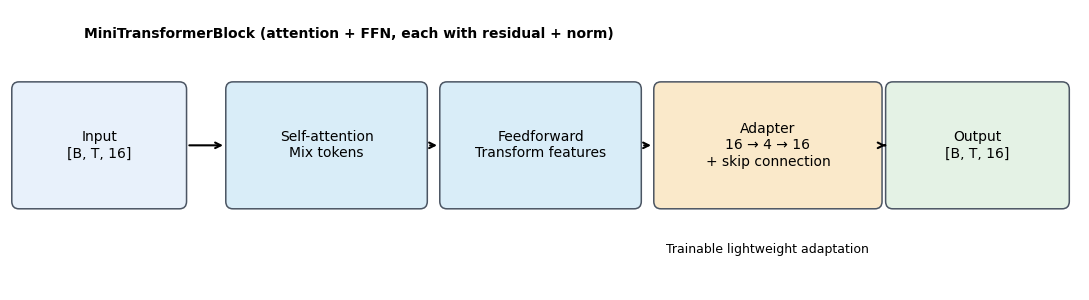

In [ ]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 3.1))
ax.set_xlim(0, 12); ax.set_ylim(0, 3); ax.axis('off')
items = [
    (0.1, 'Input\n[B, T, 16]', '#e8f1fb'),
    (2.5, 'Self-attention\nMix tokens', '#d9edf8'),
    (4.9, 'Feedforward\nTransform features', '#d9edf8'),
    (7.3, 'Adapter\n16 → 4 → 16\n+ skip connection', '#fae9ca'),
    (9.9, 'Output\n[B, T, 16]', '#e4f2e5'),
]
widths = [1.8, 2.1, 2.1, 2.4, 1.9]
for (x, label, color), w in zip(items, widths):
    patch = FancyBboxPatch((x, 0.95), w, 1.2, boxstyle='round,pad=0.08',
                           facecolor=color, edgecolor='#4b5563', linewidth=1.1)
    ax.add_patch(patch)
    ax.text(x + w/2, 1.55, label, va='center', ha='center', fontsize=10)
for (x, _, _), w, (nx, _, _) in zip(items[:-1], widths[:-1], items[1:]):
    ax.annotate('', xy=(nx - 0.08, 1.55), xytext=(x + w + 0.08, 1.55),
                arrowprops={'arrowstyle':'->', 'lw':1.5})
ax.text(3.8, 2.7, 'MiniTransformerBlock (attention + FFN, each with residual + norm)',
        ha='center', fontsize=10, fontweight='bold')
ax.text(8.5, 0.4, 'Trainable lightweight adaptation', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

### 🔌 Connect *your* Transformer to *your* adapter

Freeze the original `MiniTransformerBlock` (as if it were pretrained), then train only the adapter. **Important:** freezing prevents weight updates; it does not mean the Transformer stops participating in the forward pass.

`B` = batch size (number of sequences at once), `T` = tokens per sequence, `16` = features per token. The bottleneck compresses **features**, not tokens or batch size.

In [ ]:
class TransformerWithAdapter(nn.Module):
    def __init__(self, transformer, adapter):
        super().__init__()
        self.transformer = transformer
        self.adapter = adapter
        for p in self.transformer.parameters():
            p.requires_grad = False

    def forward(self, x):
        hidden, attention_weights = self.transformer(x)
        return self.adapter(hidden), attention_weights

combined = TransformerWithAdapter(block, adapter)
example = torch.randn(3, 5, 16)  # B=3, T=5, d_model=16
combined_output, combined_attention = combined(example)
print('Input:', tuple(example.shape), '| Output:', tuple(combined_output.shape))
print('Attention weights:', tuple(combined_attention.shape))
print('Trainable:', sum(p.numel() for p in combined.parameters() if p.requires_grad),
      '| Frozen:', sum(p.numel() for p in combined.parameters() if not p.requires_grad))
assert combined_output.shape == example.shape
assert all(not p.requires_grad for p in combined.transformer.parameters())
assert all(p.requires_grad for p in combined.adapter.parameters())

Input: (3, 5, 16) | Output: (3, 5, 16)
Attention weights: (3, 5, 5)
Trainable: 148 | Frozen: 2224


### 🔍 What happens **inside** the bottleneck?

For each token independently: **16 features → down-project to 4 → ReLU → up-project to 16 → add the original token vector**. The skip connection keeps the same shape and lets the adapter start as an identity mapping (because the up-projection was zero-initialized).


In [ ]:
# Inspect the intermediate shapes, without changing the original adapter.
with torch.no_grad():
    transformer_hidden, _ = combined.transformer(example)
    smaller = adapter.down(transformer_hidden)
    activated = F.relu(smaller)
    restored = adapter.up(activated)
    final = transformer_hidden + restored
for name, tensor in [('Transformer hidden', transformer_hidden),
                     ('Down projection', smaller), ('ReLU', activated),
                     ('Up projection', restored), ('Residual output', final)]:
    print(f'{name:20s}: {tuple(tensor.shape)}')
assert torch.allclose(final, combined_output)
print('Initial adapter correction magnitude:', restored.abs().max().item())

Transformer hidden  : (3, 5, 16)
Down projection     : (3, 5, 4)
ReLU                : (3, 5, 4)
Up projection       : (3, 5, 16)
Residual output     : (3, 5, 16)
Initial adapter correction magnitude: 0.0


## 6. 📦 Batch size: same model, more sequences at once

**Batch size** is how many training examples contribute to one optimizer update. It is **not** the number of attention heads, tokens, or bottleneck features. Here we compare batch sizes `1`, `4`, and `16` on a tiny *synthetic* binary classification task while keeping the data, model type, learning rate and **number of epochs** fixed.

Small batches have noisier updates and more optimizer steps per epoch. Large batches average over more examples but produce fewer updates. Different curves are expected; no batch size is universally best. This experiment uses a **fresh** tiny network, so it does not modify the Transformer/adapter above or the optional AdapterHub demo.

Batch  1: 64 updates/epoch; final training loss = 0.076
Batch  4: 16 updates/epoch; final training loss = 0.151
Batch 16:  4 updates/epoch; final training loss = 0.287


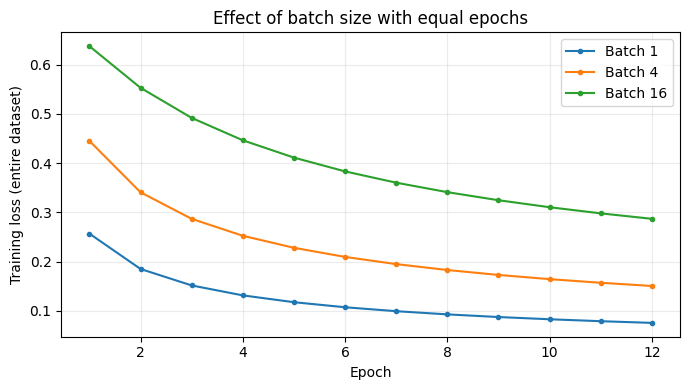

In [ ]:
# Deterministic, fast CPU demo: 64 examples, two features, binary labels.
# Only batch size changes between runs.
torch.manual_seed(2026)
features = torch.randn(64, 2)
targets = ((features[:, 0] + 0.6 * features[:, 1]) > 0).long()
batch_sizes = [1, 4, 16]
epochs = 12
histories = {}
for batch_size in batch_sizes:
    torch.manual_seed(10)  # identical starting model for fair comparison
    classifier = nn.Linear(2, 2)
    optim = torch.optim.SGD(classifier.parameters(), lr=0.1)
    losses = []
    for epoch in range(epochs):
        # Same fixed example order for each run; only grouping into batches changes.
        for start in range(0, len(features), batch_size):
            xb = features[start:start + batch_size]
            yb = targets[start:start + batch_size]
            optim.zero_grad()
            loss = F.cross_entropy(classifier(xb), yb)
            loss.backward()
            optim.step()
        with torch.no_grad():
            losses.append(F.cross_entropy(classifier(features), targets).item())
    histories[batch_size] = losses
    print(f'Batch {batch_size:2}: {len(features)//batch_size:2} updates/epoch; '
          f'final training loss = {losses[-1]:.3f}')
fig, ax = plt.subplots(figsize=(7, 4))
for batch_size, losses in histories.items():
    ax.plot(range(1, epochs + 1), losses, marker='o', ms=3,
            label=f'Batch {batch_size}')
ax.set(xlabel='Epoch', ylabel='Training loss (entire dataset)',
       title='Effect of batch size with equal epochs')
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

Why does batch size 1 usually improve faster *per epoch* here? It gets 64 updates per epoch, compared with only 4 updates for batch size 16. This is **not** a fixed-update or wall-clock benchmark. Larger batches can be computationally efficient on GPUs. Try changing `epochs` or the learning rate and compare again.


A bottleneck adapter is a small neural network added to a pretrained Transformer so we can adapt it to a new task without retraining the entire model.

The idea is to freeze the original Transformer and train only the small adapter.

## 7. 🌍 Optional real AdapterHub: tiny pretrained BERT + a task adapter

**Internet needed here.** Download [`prajjwal1/bert-tiny`](https://huggingface.co/prajjwal1/bert-tiny) (a small pretrained BERT) once. The examples below demonstrate **which parameters can train**; a few updates on a six-example toy task are **not a meaningful accuracy benchmark**.

If no internet is available during class, run everything above and discuss the code below. `adapters` may install a version of `transformers` specifically matched to it; do not separately upgrade `transformers` afterward without checking compatibility.

Useful API: `AutoAdapterModel.from_pretrained`, `add_adapter`, `add_classification_head`, `train_adapter`.

In [ ]:
# Optional pretrained demo: needs internet and the 'adapters' package.
# Uncomment and run once if needed, then restart the kernel:
# %pip install -q adapters
RUN_ADAPTERHUB = True  # Change to True only after installing adapters and downloading BERT-tiny.
print('Pretrained AdapterHub demo enabled:', RUN_ADAPTERHUB)

Pretrained AdapterHub demo enabled: True


In [ ]:
import torch
print(torch.__version__)

2.15.0+cpu


In [ ]:
if RUN_ADAPTERHUB:
    from adapters import AutoAdapterModel
    from transformers import AutoTokenizer

    model_name = 'prajjwal1/bert-tiny' #BERT-tiny: A small pretrained Transformer model that already learned general language patterns.
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoAdapterModel.from_pretrained(model_name)
    model.add_adapter('movie_mood', config='seq_bn') #movie_mood is simply the name we give the adapter. seq_bn specifies a sequential bottleneck adapter architecture.
    model.add_classification_head('movie_mood', num_labels=2) #Class 0: Negative / Class 1: Positive
    model.train_adapter('movie_mood')  # freezes backbone, trains adapter + task head
    model.set_active_adapters('movie_mood')

    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'Trainable: {trainable:,} / {total:,} = {100*trainable/total:.2f}%')
    print('Example trainable names:', [name for name, p in model.named_parameters()
                                       if p.requires_grad][:7])
else:
    print('AdapterHub demo skipped (opt in with RUN_ADAPTERHUB=True).')

There are adapters available but none are activated for the forward pass.


Trainable: 21,138 / 4,407,058 = 0.48%
Example trainable names: ['bert.encoder.layer.0.output.adapters.movie_mood.adapter_down.0.weight', 'bert.encoder.layer.0.output.adapters.movie_mood.adapter_down.0.bias', 'bert.encoder.layer.0.output.adapters.movie_mood.adapter_up.weight', 'bert.encoder.layer.0.output.adapters.movie_mood.adapter_up.bias', 'bert.encoder.layer.1.output.adapters.movie_mood.adapter_down.0.weight', 'bert.encoder.layer.1.output.adapters.movie_mood.adapter_down.0.bias', 'bert.encoder.layer.1.output.adapters.movie_mood.adapter_up.weight']


### ⚡ Micro-training demo 

A miniature sentiment classification exercise. For serious evaluation, use separate training/test data and real labels. This cell only proves that gradients update the adapter/head while the base remains frozen.

In [ ]:
if RUN_ADAPTERHUB:
    sentences = [
        'I loved this movie', 'What a wonderful film', 'The acting was fantastic',
        'I hated this movie', 'A boring terrible film', 'The acting was awful'
    ]
    labels = torch.tensor([1, 1, 1, 0, 0, 0])
    batch = tokenizer(sentences, padding=True, truncation=True, return_tensors='pt')
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=1e-3)
    model.train()
    for step in range(12):
        optimizer.zero_grad()
        outputs = model(**batch, labels=labels)
        outputs.loss.backward()
        optimizer.step()
        if step in (0, 5, 11):
            print(f'Step {step+1:2} | training loss {outputs.loss.item():.3f}')
    model.eval()
    with torch.no_grad():
        scores = torch.softmax(model(**tokenizer(['A lovely film', 'An awful movie'],
                                                       padding=True, return_tensors='pt')).logits, dim=-1)
    print('Toy predictions [negative, positive]:\n', scores.round(decimals=3))
else:
    print('Set RUN_ADAPTERHUB=True in the previous cell to train the adapter.')

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Step  1 | training loss 0.675
Step  6 | training loss 0.660
Step 12 | training loss 0.621
Toy predictions [negative, positive]:
 tensor([[0.4450, 0.5550],
        [0.5410, 0.4590]])
